In [1]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2 qiskit-ibm-runtime==0.50.0


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT))

# 06 · Does our charging plan survive a real quantum chip?

**Motivation.** Notebook 05 predicted, with the `FakeFez` simulator, how our QAOA circuits would behave on IBM's 156-qubit *Fez* processor. A simulator is only a snapshot of a device's error rates, so here we run the same circuits on the real `ibm_fez` chip and check the prediction.

**Workflow.**
1. Submit the study-05 circuits (same mixer, start state, depth, angle seed and compiler seed) to `ibm_fez` in one job, with dynamical decoupling (XpXm) and gate + measurement twirling switched on, plus two readout-calibration circuits (all 0s, all 1s).
2. Record what ran: backend, job id, shots, error-suppression settings and the compiled circuit size.
3. Rebuild each circuit's perfect (statevector) output and its FakeFez output.
4. Score ideal vs FakeFez vs the real chip (raw, readout-corrected, and with invalid shots discarded).
5. Compare the distributions: top-10 schedules and Hellinger fidelity.

**Zero QPU time by default.** With `RUN_ON_IBM = False` the notebook replays the counts saved in `results/06_hardware/hw_counts.json`, so anyone can re-run it without an IBM account.

### Running it on your own IBM account
The notebook never contains a token. It reads the account you saved once on your own machine (stored in `~/.qiskit/qiskit-ibm.json`). To save yours, run this **once in a terminal**, not in the notebook:

```python
from qiskit_ibm_runtime import QiskitRuntimeService
QiskitRuntimeService.save_account(channel='ibm_quantum_platform', token='<your API key>',
                                  instance='<your instance CRN>', set_as_default=True)
```

Then set `RUN_ON_IBM = True` below. The job uses about a minute of QPU time and may wait in the queue. It overwrites `jobs.json` and `hw_counts.json` in the data folder.

In [3]:
import os, json, time
import numpy as np
import matplotlib.pyplot as plt
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeFez
from evqaoa import DEPOT, output_distribution
from experiments import hardware
from experiments.noise import setup, transpile_for, circuit_stats, sample, correct_readout
from experiments.hardware_analysis import (LABELS, analyse_run, record_table, run_names, study05_row,
                                           top_schedules, plot_metric_bars, plot_fidelity,
                                           plot_top_schedules)

RUN_ON_IBM = False        # True = submit to the real chip (uses QPU time); False = replay saved counts
BACKEND_NAME = 'ibm_fez'
# data + outputs live here; EVQAOA_HW_DIR lets you point the notebook at another folder
OUT = pathlib.Path(os.environ.get('EVQAOA_HW_DIR', ROOT / 'results' / '06_hardware'))
OUT.mkdir(parents=True, exist_ok=True)
model, _, base = setup()
RANDOM_VALID = base.n_valid / 2 ** DEPOT.n_qubits
print(f'data folder: {OUT.relative_to(ROOT) if OUT.is_relative_to(ROOT) else OUT}')
print(f'runs defined: {list(hardware.RUNS)}')

data folder: results/06_hardware
runs defined: ['xy_dicke_p2', 'xy_dicke_p1', 'x_penalty_p2']


## Step 1 · Run on the chip, or load the saved counts
All runs and both calibration circuits go into **one** Sampler job, so they see the same device calibration.

In [4]:
if RUN_ON_IBM:
    from qiskit_ibm_runtime import QiskitRuntimeService
    backend = QiskitRuntimeService().backend(BACKEND_NAME)   # account from ~/.qiskit, never a token here
    job = hardware.submit_runs(backend, list(hardware.RUNS), shots=hardware.SHOTS, out_dir=OUT)
    print(f'submitted job {job.job_id()} to {backend.name}; waiting for it to finish ...')
    t0 = time.time()
    job.result()                                              # blocks until the job is done
    print(f'job finished after {time.time()-t0:.0f}s')
    hardware.collect(out_dir=OUT)
hw = json.loads((OUT / 'hw_counts.json').read_text())
jobs_path = OUT / 'jobs.json'
jobs = json.loads(jobs_path.read_text()) if jobs_path.exists() else {}
RUN_NAMES = run_names(hw)
print(f'loaded {len(RUN_NAMES)} runs: {RUN_NAMES}')

loaded 3 runs: ['xy_dicke_p2', 'xy_dicke_p1', 'x_penalty_p2']


## Step 2 · What ran
Two-qubit gates and depth are counted on the circuit exactly as compiled for the chip.

In [5]:
records = record_table(hw)
first = hw[RUN_NAMES[0]]
print(f"backend {first['backend']} | job {first['job_id']} | submitted {jobs.get('timestamp_utc', 'n/a')}")
usage = hw.get('usage', {})
print(f"QPU time charged: {usage.get('qpu_charge_time_seconds', usage.get('quantum_seconds', 'n/a'))} s")
print(f"{'run':14s} {'backend':10s} {'job id':22s} shots  error suppression             2q-gates depth")
for r in records:
    print(f"{r['run']:14s} {r['backend']:10s} {r['job_id']:22s} {r['shots']:5d}  "
          f"{r['error_suppression']:28s} {r['two_qubit_gates']:8d} {r['depth']:5d}")
cal = hw.get('readout_calibration', {})
HAS_CAL = {'counts_all0', 'counts_all1'} <= set(cal)
print(f"readout calibration: {'yes, ' + str(len(cal['physical_qubits'])) + ' qubits' if HAS_CAL else 'not present'}")

backend ibm_fez | job dbe13vvgdj9s73fl0mt0 | submitted 2026-10-24T02:03:43.993873+00:00
QPU time charged: 8 s
run            backend    job id                 shots  error suppression             2q-gates depth
xy_dicke_p2    ibm_fez    dbe13vvgdj9s73fl0mt0    4096  DD XpXm, twirling gate+measure      357   387
xy_dicke_p1    ibm_fez    dbe13vvgdj9s73fl0mt0    4096  DD XpXm, twirling gate+measure      209   282
x_penalty_p2   ibm_fez    dbe13vvgdj9s73fl0mt0    4096  DD XpXm, twirling gate+measure      305   486
readout calibration: yes, 24 qubits


## Step 3 · Rebuild the perfect and FakeFez outputs
`hardware.build_run` re-optimises the angles with the same seed as study 05, so these are the angles that were sent to the chip. FakeFez uses the same compiler seed, so its circuit should have the same gate count as the one that ran.

In [6]:
fake = FakeFez()
fake_sim = AerSimulator.from_backend(fake)
ideal, fakefez, fakefez_stats = {}, {}, {}
t0 = time.time()
for name in RUN_NAMES:
    circ, theta = hardware.build_run(name)
    ideal[name] = output_distribution(circ, theta)
    tc = transpile_for(circ, theta, fake, seed=hardware.TRANSPILE_SEED)
    fakefez[name], fakefez_stats[name] = sample(tc, fake_sim, hw[name]['shots']), circuit_stats(tc)
    print(f"{name:14s} FakeFez 2q-gates {fakefez_stats[name]['two_qubit_gates']:4d} "
          f"| chip 2q-gates {hw[name]['circuit_stats']['two_qubit_gates']:4d}")
print(f'rebuild + FakeFez sampling took {time.time()-t0:.0f}s')

xy_dicke_p2    FakeFez 2q-gates  357 | chip 2q-gates  357


xy_dicke_p1    FakeFez 2q-gates  209 | chip 2q-gates  209


x_penalty_p2   FakeFez 2q-gates  305 | chip 2q-gates  305
rebuild + FakeFez sampling took 89s


## Step 4 · Score every source
Same scores as study 05, always with the penalty-free cost: valid share, P(optimal), P(optimal) after discarding invalid shots, approximation ratio. Readout correction inverts each qubit's measured flip rates from the calibration circuits. For reference, a random 12-bit guess is valid 3.5% of the time.

In [7]:
study05 = json.loads((ROOT / 'results' / '05_noise' / 'noisy_results.json').read_text())['rows']
results, tops = {}, {}
for name in RUN_NAMES:
    entry = hw[name]
    dists = dict(ideal=ideal[name], fakefez=fakefez[name], hardware=entry['counts'])
    if HAS_CAL:
        rates = hardware.readout_rates(cal, entry['physical_qubits'])
        dists['hardware_readout'] = correct_readout(entry['counts'], rates)
    results[name] = analyse_run(dists, model, base)
    tops[name] = top_schedules(ideal[name], dists, k=10)
print(f"{'run':14s} {'source':32s} valid  P(opt) P(opt|valid) approx")
for name in RUN_NAMES:
    for src, s in results[name]['scores'].items():
        print(f"{name:14s} {LABELS[src]:32s} {s['valid_rate']:.3f}  {s['p_optimal']:.3f}  "
              f"{s['p_optimal_valid']:.3f}        {s['approx_ratio']:.3f}")
    h = results[name]['hellinger']
    print(f"{'':14s} Hellinger: chip vs ideal {h['hardware_vs_ideal']:.3f} | chip vs FakeFez "
          f"{h['hardware_vs_fakefez']:.3f} | FakeFez vs ideal {h['fakefez_vs_ideal']:.3f}")
print('\ncross-check against study 05 (FakeFez valid share):')
for name in RUN_NAMES:
    cfg = hardware.RUNS[name]
    row = study05_row(study05, cfg['fakefez_config'], cfg['reps'])
    here = results[name]['scores']['fakefez']['valid_rate']
    print(f"{name:14s} here {here:.3f} | study 05 {row['valid_rate']:.3f}" if row else f'{name:14s} not in study 05')

run            source                           valid  P(opt) P(opt|valid) approx
xy_dicke_p2    ideal simulator                  1.000  0.104  0.104        0.807
xy_dicke_p2    FakeFez (noisy sim)              0.341  0.028  0.082        0.779
xy_dicke_p2    ibm_fez raw                      0.169  0.012  0.069        0.757
xy_dicke_p2    ibm_fez readout-corrected        0.179  0.013  0.072        0.760
xy_dicke_p2    ibm_fez invalid shots discarded  1.000  0.069  0.069        0.757
               Hellinger: chip vs ideal 0.137 | chip vs FakeFez 0.464 | FakeFez vs ideal 0.316
xy_dicke_p1    ideal simulator                  1.000  0.033  0.033        0.719
xy_dicke_p1    FakeFez (noisy sim)              0.510  0.018  0.036        0.710
xy_dicke_p1    ibm_fez raw                      0.261  0.008  0.031        0.701
xy_dicke_p1    ibm_fez readout-corrected        0.285  0.009  0.031        0.701
xy_dicke_p1    ibm_fez invalid shots discarded  1.000  0.031  0.031        0.701
             

## Step 5 · Plots

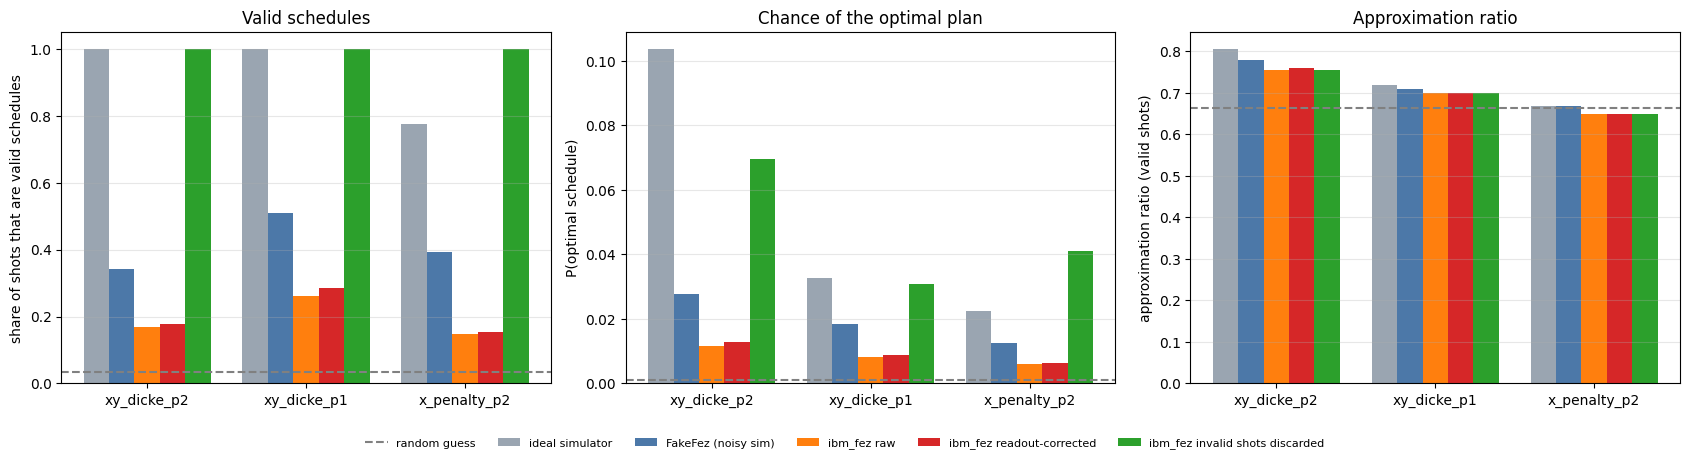

In [8]:
reference = dict(valid_rate=RANDOM_VALID, p_optimal=base.n_optimal / 2 ** DEPOT.n_qubits,
                 approx_ratio=(base.worst - base.mean) / (base.worst - base.best))
plot_metric_bars(results, OUT / 'hardware_vs_simulators.png', reference=reference)
plt.show()

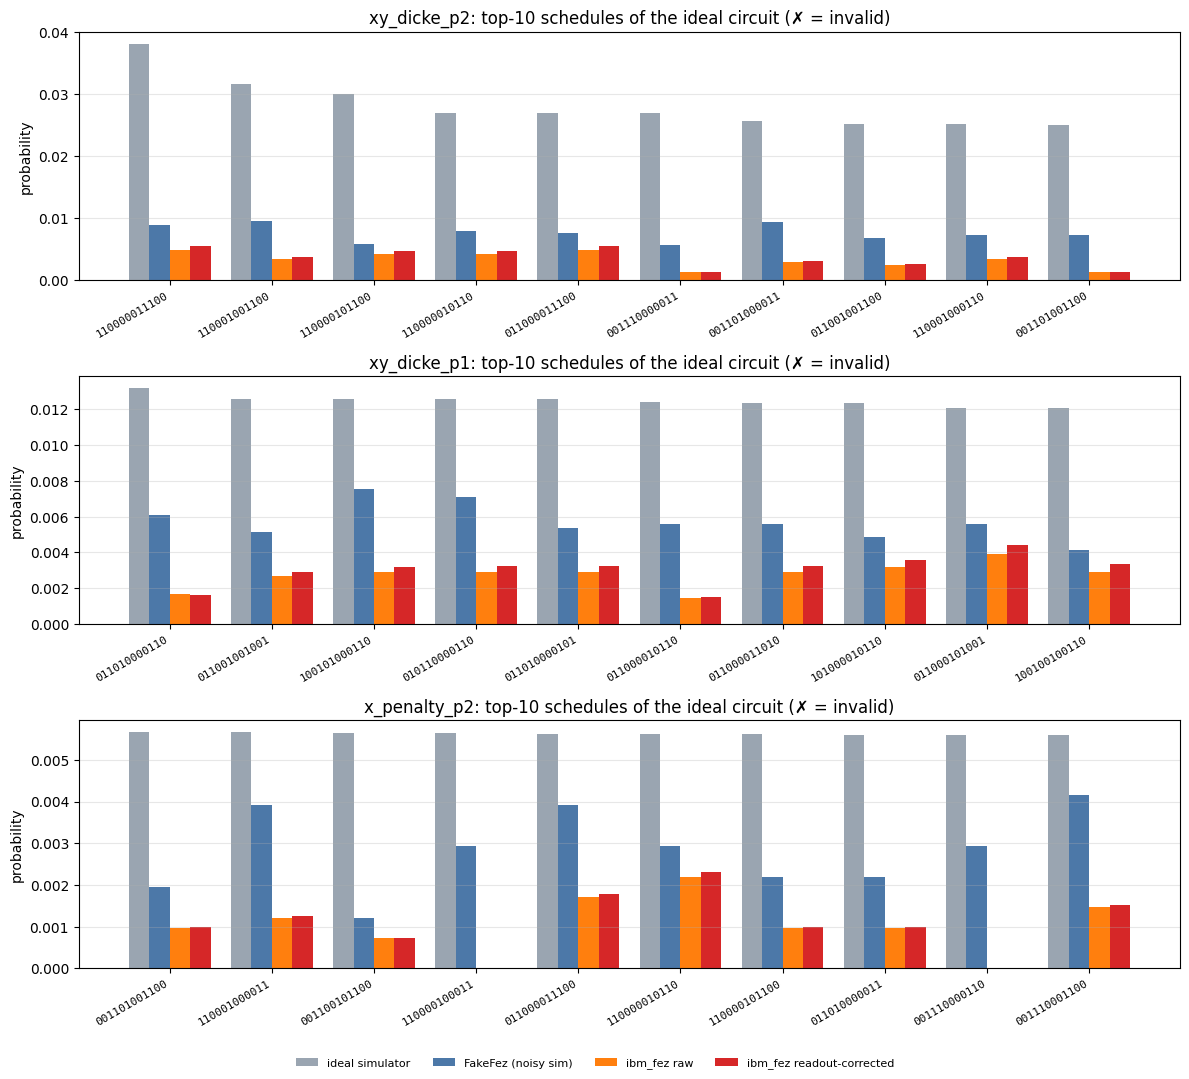

In [9]:
plot_top_schedules(tops, OUT / 'top10_schedules.png')
plt.show()

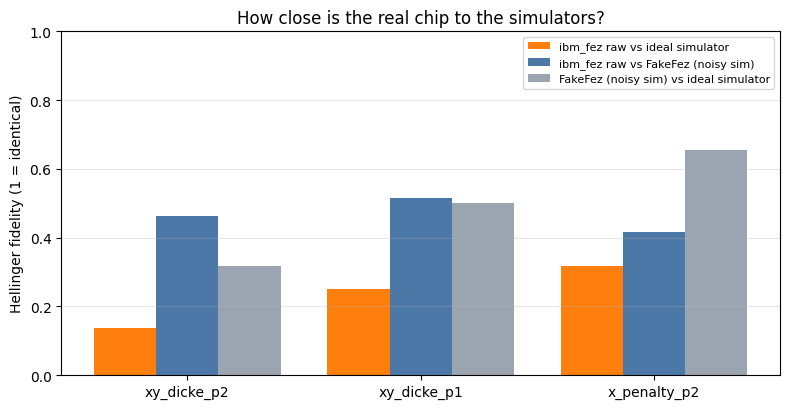

In [10]:
plot_fidelity(results, OUT / 'hellinger_fidelity.png')
plt.show()

## Step 6 · Save every number

In [11]:
summary = dict(backend=first['backend'], job_id=first['job_id'], shots=first['shots'],
               options=first['options'], timestamp_utc=jobs.get('timestamp_utc'),
               usage=hw.get('usage'), readout_corrected=HAS_CAL, random_valid_rate=RANDOM_VALID,
               runs={})
for name, rec in zip(RUN_NAMES, records):
    cfg = hardware.RUNS[name]
    summary['runs'][name] = dict(config=cfg, record=rec, fakefez_circuit_stats=fakefez_stats[name],
                                 study05_fakefez=study05_row(study05, cfg['fakefez_config'], cfg['reps']),
                                 top10=tops[name], **results[name])
(OUT / 'hardware_results.json').write_text(json.dumps(summary, indent=2))
print('saved', sorted(p.name for p in OUT.iterdir()))

saved ['hardware_results.json', 'hardware_vs_simulators.png', 'hellinger_fidelity.png', 'hw_counts.json', 'jobs.json', 'top10_schedules.png']


## Findings & limitations

**Run record.** One SamplerV2 job on real **ibm_fez** (job `dbe13vvgdj9s73fl0mt0`), 4,096 shots per circuit, dynamical decoupling (XpXm) plus gate and measurement twirling. The job held 3 QAOA circuits and 2 readout-calibration circuits and used **8 s of QPU time**.

**What we found**

1. **Real hardware keeps about half the valid share FakeFez predicts.** The main circuit (XY mixer, Dicke start, p = 2, 357 two-qubit gates) gave 16.9% valid plans on the chip against 34.1% on FakeFez. The p = 1 circuit gave 26.1% against 51.0%, and the penalty baseline 14.9% against 39.1%. FakeFez is too optimistic by about 2× for all three, so noisy-simulator numbers should be treated as an upper bound.
2. **The structure survives the noise.** Every circuit is still far above a random 12-bit guess (3.5% valid). The three circuits rank in the same order on the chip as on FakeFez for valid share, P(optimal) and approximation ratio.
3. **Discarding invalid shots recovers the useful signal.** After post-selection, the main circuit finds the optimal plan **6.9%** of the time, 2.5× a random valid plan (2.8%) and close to FakeFez (8.2%). Only the XY + Dicke p = 2 circuit beats random by a clear margin. The p = 1 and penalty circuits sit at 3.1% and 4.1%.
4. **Readout error is not the bottleneck.** Measured flip rates are about 1.5% per qubit, and readout correction adds only 0.4–2.4 points of valid share. Most of the loss comes from two-qubit gate errors and decoherence over 280–490 layers of depth.
5. **Shallower is more valid but less optimal.** p = 1 keeps the most valid shots on the chip, while p = 2 keeps more of its optimisation quality after post-selection. This is the depth trade-off on current hardware.

**Limitations**

- A single job on a single day. Calibration on IBM chips drifts, so the numbers carry device-to-device and day-to-day variation that we did not measure.
- The angles were tuned on a perfect simulator, not on the chip. Training them on hardware or with noise included might do better.
- Only the error suppression built into Qiskit Runtime was used (DD, twirling) plus readout correction. Zero-noise extrapolation and other mitigation were not tried.
- With 4,096 shots, the post-selected P(optimal) rests on about 690 valid shots for the main run, so its sampling error is roughly ±1 percentage point.
